In [4]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import os
# import plotly.express as px
import xgboost as xgb


pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
%config Completer.use_jedi = False

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from sklearn.ensemble import GradientBoostingRegressor

In [5]:
import seaborn as sns

# Loading Data For 1186 and 1183 ,

In [6]:
# AE data
ae_data = pd.read_csv('C:\\Users\\Devesh\\Downloads\\AE_intermediate_data.csv')
ae_data.drop(columns = ['any_ae','sev_fatal', 'sev_life_threatning', 'sev_mild', 'sev_moderate', 'sev_severe','AESER','SAELIFE'],inplace=True)
ae_data.fillna(0,inplace=True)
ae_data.head()

,SUBJID,ae_month,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,201001001,month1,1.0,1.0,0.0,1.0,2,1.0,0,1,6.0,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,3,0
1,201001001,month2,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
2,201001001,month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
3,201001001,>month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
4,201001001,month4,11.0,11.0,0.0,0.0,0,1.0,0,0,6.0,65.777778,181.091714,1982.449216,2416.611468,26442.364034,402.430451,4405.475769,0.0,0.0,401.774088,4404.163042,1,0


In [9]:
medhist = pd.read_csv('C:\\Users\\Devesh\\Downloads\\ML_kolate\\code\\code\\NCT00339183 - 1186\\medical_intermediate.csv')
demobl = pd.read_csv('C:\\Users\\Devesh\\Downloads\\ML_kolate\\code\\code\\NCT00339183 - 1186\\demography_intermediate2.csv')
demobl.drop(columns = ['STUDYID','SITEID','SEXCD','RACCATCD','TRTFRQCD','TRTCD','TRT','TRTFREQ','ATRTCD',\
                      'PRBEVCDR','PRBEVCDM','PROXACDR','PROXACDM','PROXALCD','LIVRONCD','PADJYNCD',\
                       'BECOGICD','DIAGTYCD','TUMCATCD','KRASCD','B_ECOGCD','HISTYPCD','HISSBTCD','HDIFFCD','BIOPPNO',\
                      'BIOPPFCD','BIOPHFCD','BIOPBSCD','BIOPEFCD','BIOPPCCD','BIOPCYCD','PREGTYCD','PREGRSCD','BIORSNCD'],inplace=True)
for col in demobl.columns:
    demobl[col].replace({True:1,False:0,'N':0,'Y':1,'Positive':1,'Negative':0},inplace=True)
    demobl[col].fillna(0,inplace=True)

In [10]:
m1_ae = ae_data[ae_data['ae_month'] == 'month1'].copy()
m1_ae.drop(columns=['ae_month',],inplace=True)
ID = 'SUBJID'
TARGET = 'total_AE'
other_Cols = ['total_SAE']

fin_df = pd.merge(demobl,medhist,on=['SUBJID'],how='left')
fin_df = pd.merge(fin_df,m1_ae,on=['SUBJID'],how='inner')
fin_df.columns = fin_df.columns.str.replace(" ", "_")
fin_df.columns = fin_df.columns.str.replace("<", "lessthan")
fin_df.drop(columns=['BIOPF', 'BIOPHF', 'BIOPRS', 'BIOPEF'],inplace=True)
fin_df.drop(columns=['Unnamed:_0'],inplace=True)

In [11]:
fin_df

,SUBJID,AGE,TRTDOSE,PRBEVR,PRBEVM,PRBEVCD,PROXAR,PROXAM,B_METANM,LIVRONLY,PRADJYN,DPADJUV,B_LDHYN,B_LDH2YN,B_LDHNM,TUMCAT,LIVERMET,EVALITT,EVALPP,EVALQOL,EVALEGFR,TRTDUR,B_WEIGHT,B_HEIGHT,B_BSA,DIAGMONS,METMONS,BIOPACPT,BIOPHACT,BIOPSTCD,BIOPTPCT,BIOPRSCD,BIOPNEG,BIOPWEAK,BIOPMOD,BIOPSTRG,BIOP3,BIOPS123,BIOPCYTO,H11NEG,H11WEAK,H11MOD,UGT1A1YN,CHILDPOT,PREGDONE,BIONANY,diagdy,metdxdy,biopdy,biopdy2,PREGDY,HDIFFER_Poorly_differentiated,HDIFFER_Undifferentiated,HDIFFER_Unknown,HDIFFER_Well_differentiated,HISSUBTY_Mucinous,HISSUBTY_No_sub-type,HISSUBTY_Other,HISSUBTY_Unknown,BIOPNO_100-500_cells_present,BIOPNO_50-99_cells_present,BIOPNO_>500_cells_present,BIOPPCT_lessthan10%,BIOPPCT_>35%,BIOPCY_lessthan10%,BIOPCY_>35%,BIOPMAX_1+,BIOPMAX_2+,BIOPMAX_3+,BIOPSITE_Primary,B_ECOG_In_bed,B_ECOG_Symptoms_but_ambulatory,PREGRES_Not_applicable,SEX_Female,SEX_Male,RACCAT_Other,RACCAT_White_or_Caucasian,ATRT_FOLFIRI_alone,ATRT_Panitumumab_+_FOLFIRI,PRBEV_N,PRBEV_Y,PROXAL_N,PROXAL_Y,B_METACT_1,B_METACT_2,B_METACT_>=3,B_ECOGI_Fully_active,B_ECOGI_In_bed_less_than_50%_of_the_time,B_ECOGI_Symptoms_but_ambulatory,BECGICT_0_or_1,BECGICT_2,DIAGTYPE_Colon,DIAGTYPE_Rectal,KRAS_Failed,KRAS_Mutant,KRAS_Wild-type,BIOPMAXC_0,BIOPMAXC_1+,BIOPMAXC_2+,BIOPMAXC_3+,BIOPBSIT_Anus,BIOPBSIT_Bone,BIOPBSIT_Breast,BIOPBSIT_Colon,BIOPBSIT_Liver,BIOPBSIT_Lung_parenchyma,BIOPBSIT_Lymph_Nodes,BIOPBSIT_Other,BIOPBSIT_Peritoneum,BIOPBSIT_Pleural_effusion,BIOPBSIT_Rectum,BIOPBSIT_Small_Intestine,BIOPBSIT_Stomach,PREGTYPE_Pregnancy_-_Serum,PREGTYPE_Pregnancy_-_Urine,MHANY,MHBNGNYN,MHBODSYS_Dermatologic,MHBODSYS_Endocrine/Metabolic,MHBODSYS_Gastrointestinal,MHBODSYS_Genitourinary/Reproductive,MHBODSYS_Hematologic/Lymphatic,MHBODSYS_Hepatic/Biliary,MHBODSYS_Immunologic,MHBODSYS_Musculoskeletal,MHBODSYS_Neurologic,MHBODSYS_Other,MHBODSYS_Psychiatric,MHBODSYS_Renal,MHBODSYS_Respiratory,MHBODSYS_Special_Senses,MHCOND_Benign_bone_lesions,MHCOND_Benign_liver_lesions,MHCOND_Benign_lung_lesions,MHCOND_Benign_mediastinal_and_hilar_masses/nodules,MHCOND_Benign_renal_lesions,MHCOND_Benign_retroperitoneal_abnormalities,MHCOND_Other,"MHCOND_Post-surgical._-procedural,_or_-inflammatory_fibrosis_or_scarring",MHCOND_Post-traumatic_hematomas,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,MHSITE_Chest_wall,MHSITE_Colon,MHSITE_Esophagus,MHSITE_Gall_bladder,MHSITE_Kidney,MHSITE_Liver,MHSITE_Lung_parenchyma,MHSITE_Lymph_Nodes,MHSITE_Other,MHSITE_Pancreas,MHSITE_Pelvis,MHSITE_Pericardial_Effusion,MHSITE_Peritoneum,MHSITE_Pleura_or_pleural_wall,MHSITE_Rectum,MHSITE_Skin,MHSITE_Small_Intestine,MHSITE_Spinal_cord,MHSITE_Spleen,MHSITE_Thyroid,MHSTAT_Resolved,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,201001001,54.0,6.0,1,1,1.0,1,1,4.0,0,0,0.0,0.0,0.0,187.0,1,1,1,1,1,1,219.0,80.0,182.0,2.011080,9.540984,9.540984,1.0,1.0,1.0,61.28,1.0,85.3,9.8,5.0,0.0,0.0,14.8,2.1,97.9,2.1,0.0,0.0,0.0,0.0,0.0,-293.0,-293.0,644.0,667.0,0.0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,1.0,0.0,1.0,2,1.0,0,1,6.000000,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,3,0
1,201001002,66.0,6.0,1,1,1.0,1,1,3.0,0,0,0.0,0.0,0.0,215.0,1,1,1,1,1,1,60.0,93.0,178.0,2.144372,6.131148,6.131148,1.0,1.0,1.0,43.22,1.0,99.9,0.1,0.0,0.0,0.0,0.1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-193.0,-193.0,670.0,698.0,0.0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3.0,3.0,0.0,0.0,2,0.0,0,2,6.000000,18.000000,177.226673,531.680019,2363.036295,7089

In [12]:
fin_df['AGE']

0      54.0
1      66.0
2      58.0
3      75.0
4      52.0
       ... 
920    52.0
921    52.0
922    62.0
923    39.0
924    74.0
Name: AGE, Length: 925, dtype: float64

In [13]:
fin_df.rename(columns={'total_AE': 'Total_AE'}, inplace=True)

In [14]:
X = fin_df.drop(['Total_AE', 'total_SAE'], axis=1)
y_ae = fin_df['Total_AE']

In [15]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=100,max_depth= 5, random_state=42)
rf_ae.fit(X, y_ae)
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

print("Top features for total_AE:")
print(feature_importance_ae.head(30))

Top features for total_AE:
                   feature  importance
170                AERELCM    0.562738
172                AEACT03    0.333495
169                  AEREL    0.022409
180               AEFBCDOS    0.007806
178               AEFICDOS    0.006308
175               AEIRWDOS    0.005043
0                   SUBJID    0.004118
179               AEFBWDOS    0.003668
21                  TRTDUR    0.003352
177               AEFIWDOS    0.003237
176               AEIRCDOS    0.003205
23                B_HEIGHT    0.003092
14                 B_LDHNM    0.002753
8                 B_METANM    0.002647
166     prior_chemo_cycles    0.002642
1                      AGE    0.002528
24                   B_BSA    0.002105
25                DIAGMONS    0.002091
49                 biopdy2    0.001495
46                  diagdy    0.001388
30                BIOPTPCT    0.001306
174                 AECDOS    0.001238
183               AEDLWDOS    0.001040
48                  biopdy    0.00091

In [16]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()

In [17]:
top_features_ae.append('Total_AE')

In [18]:
aa = fin_df[top_features_ae]

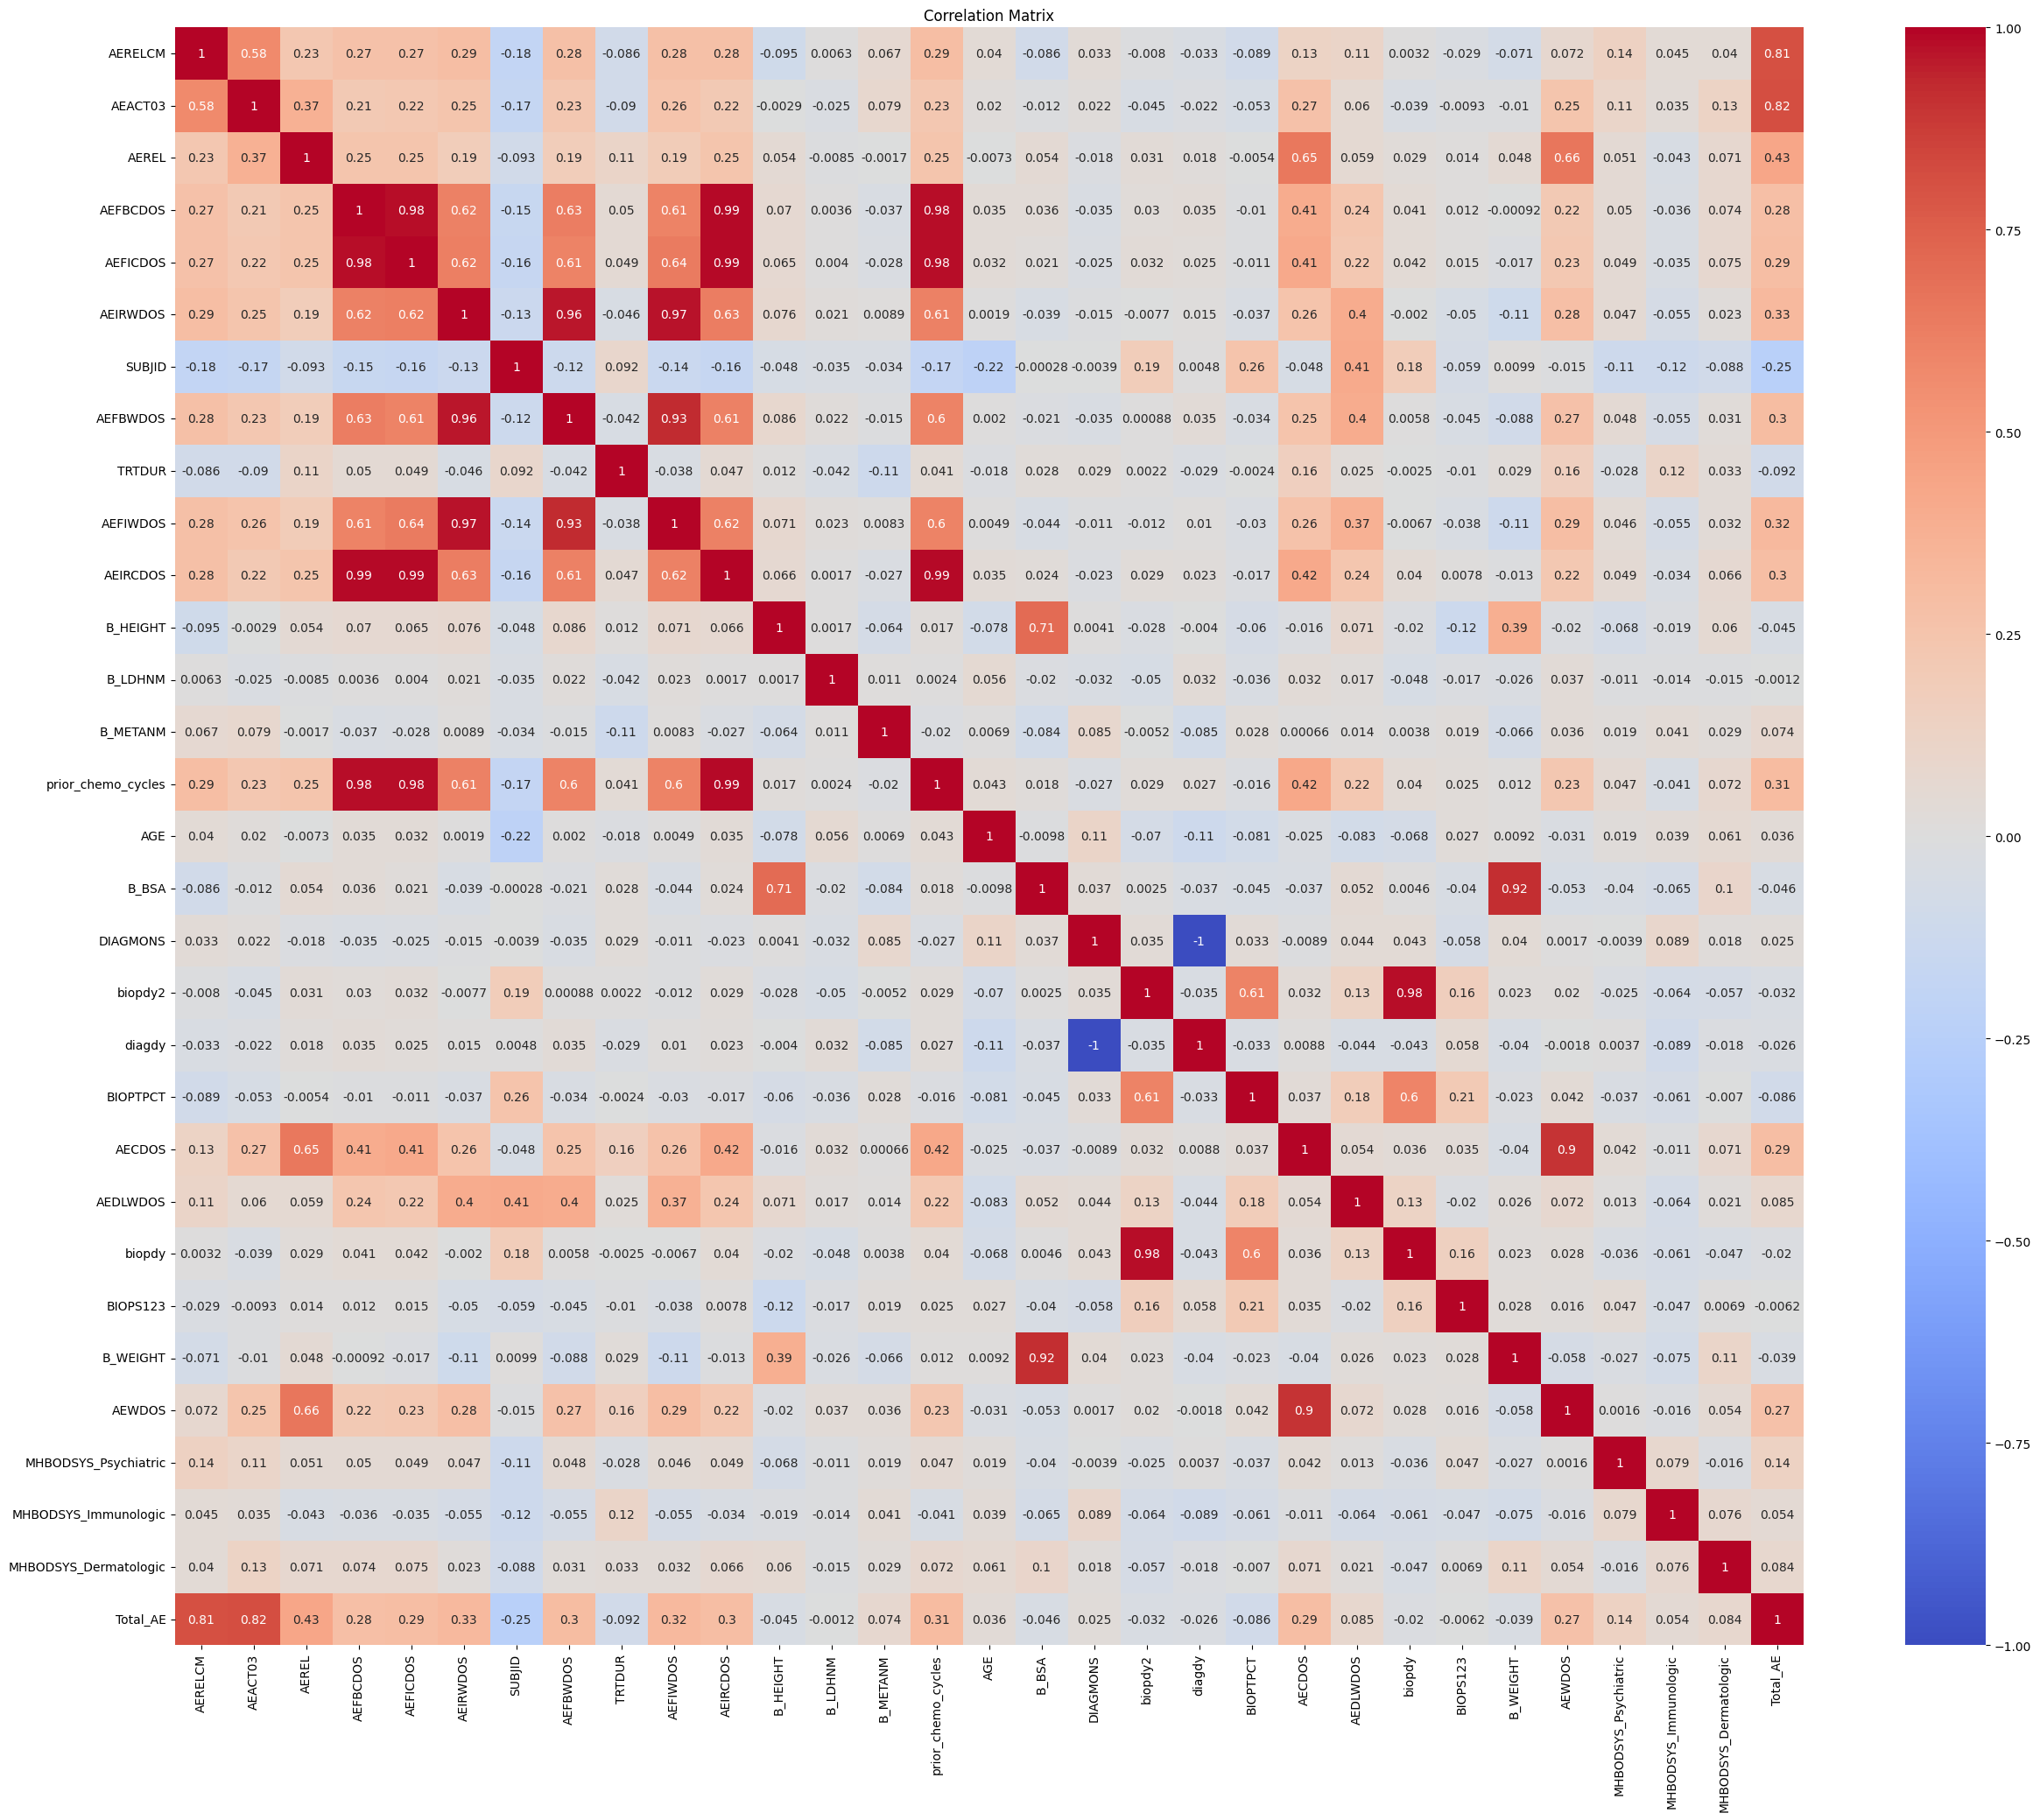

In [19]:
corr_matrix = aa.corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(30, 24))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix')
plt.show()

In [20]:
len(demobl['SUBJID'].unique())

946

Reading data for 1183

In [27]:
adae = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adae_pds2019.csv")
adlb = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adlb_pds2019.csv")
adls = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adls_pds2019.csv")
adpm = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adpm_pds2019.csv")
adrsp = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adrsp_pds2019.csv")
adsl = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adsl_pds2019.csv")

def categorize_month(days):
    if 0 <= days <= 30:
        return 'month1'
    elif 31 <= days <= 60:
        return 'month2'
    else:
        return 'month>2'

# Apply the function to the 'AEENDYI' column and create a new 'Month' column
adae['Month'] = adae['AESTDYI'].apply(categorize_month)

adae = adae.drop(columns=['AEENDYI'])

rows_with_nan = adae[adae.isna().any(axis=1) | (adae == '').any(axis=1)]
adae = adae.dropna()
# Drop rows with any blank values
adae = adae[~(adae == '').any(axis=1)]

adae_Y = adae.drop(columns=['AECONT'])
adae_Y.head()
adae_Y.drop(columns=['AEPT'], inplace=True)

adae_Y['Total_AE'] = adae_Y.groupby(['SUBJID', 'Month'])['AESOC'].transform('nunique')

adae_Y = adae_Y.drop_duplicates(subset=['SUBJID', 'Month'])

unique_subjids = adae_Y['SUBJID'].unique()
month_categories = ['month1', 'month2', 'month>2']

# Create a DataFrame with all combinations of SUBJID and month categories
all_combinations = pd.MultiIndex.from_product([unique_subjids, month_categories], names=['SUBJID', 'Month']).to_frame(index=False)

# Merge with the original DataFrame
merged = all_combinations.merge(adae_Y, on=['SUBJID', 'Month'], how='left')

# Fill missing values
merged['AESOC'] = merged['AESOC'].fillna('')  # Or any default value you prefer
merged['AESTDYI'] = merged['AESTDYI'].fillna(0)
merged['AESEVCD'] = merged['AESEVCD'].fillna(0)
merged['Total_AE'] = merged['Total_AE'].fillna(0)

# Display the resulting DataFrame
print(merged)

adae1 = merged.drop(columns=['AESTDYI', 'AESEVCD'])

final_df = pd.merge(adae1, adsl, on='SUBJID', how='left')
adae_Y = adae.drop(columns=['AECONT'])
adae_Y.drop(columns=['AEPT'], inplace=True)

adae_Y['Total_AE'] = adae_Y.groupby(['SUBJID', 'Month'])['AESOC'].transform('nunique')

adae_Y = adae_Y.drop_duplicates(subset=['SUBJID', 'Month'])

unique_subjids = adae_Y['SUBJID'].unique()
month_categories = ['month1', 'month2', 'month>2']

# Create a DataFrame with all combinations of SUBJID and month categories
all_combinations = pd.MultiIndex.from_product([unique_subjids, month_categories], names=['SUBJID', 'Month']).to_frame(index=False)

# Merge with the original DataFrame
merged = all_combinations.merge(adae_Y, on=['SUBJID', 'Month'], how='left')

# Fill missing values
merged['AESOC'] = merged['AESOC'].fillna('')  # Or any default value you prefer
merged['AESTDYI'] = merged['AESTDYI'].fillna(0)
merged['AESEVCD'] = merged['AESEVCD'].fillna(0)
merged['Total_AE'] = merged['Total_AE'].fillna(0)


      SUBJID    Month                                   AESOC  AESTDYI  AESEVCD  Total_AE
0          3   month1  Skin and subcutaneous tissue disorders     12.0      1.0       1.0
1          3   month2  Skin and subcutaneous tissue disorders     41.0      1.0       1.0
2          3  month>2                                              0.0      0.0       0.0
3          7   month1  Skin and subcutaneous tissue disorders      9.0      1.0       1.0
4          7   month2                                              0.0      0.0       0.0
...      ...      ...                                     ...      ...      ...       ...
1819    1181   month2  Skin and subcutaneous tissue disorders     36.0      1.0       1.0
1820    1181  month>2  Skin and subcutaneous tissue disorders     81.0      2.0       1.0
1821    1182   month1                                              0.0      0.0       0.0
1822    1182   month2                                              0.0      0.0       0.0
1823    11

In [28]:
def categorize_month(days):
    if 0 <= days <= 30:
        return 'month1'
    elif 31 <= days <= 60:
        return 'month2'
    else:
        return 'month>2'

In [29]:
adae1 = merged.drop(columns=['AESTDYI', 'AESEVCD'])

In [32]:
# Apply the function to the 'AEENDYI' column and create a new 'Month' column
adae['Month'] = adae['AESTDYI'].apply(categorize_month)

rows_with_nan = adae[adae.isna().any(axis=1) | (adae == '').any(axis=1)]
adae = adae.dropna()
# Drop rows with any blank values
adae = adae[~(adae == '').any(axis=1)]

adae_Y = adae.drop(columns=['AECONT'])
adae_Y.head()
adae_Y.drop(columns=['AEPT'], inplace=True)

adae_Y['Total_AE'] = adae_Y.groupby(['SUBJID', 'Month'])['AESOC'].transform('nunique')

adae_Y = adae_Y.drop_duplicates(subset=['SUBJID', 'Month'])

unique_subjids = adae_Y['SUBJID'].unique()
month_categories = ['month1', 'month2', 'month>2']

# Create a DataFrame with all combinations of SUBJID and month categories
all_combinations = pd.MultiIndex.from_product([unique_subjids, month_categories], names=['SUBJID', 'Month']).to_frame(index=False)

# Merge with the original DataFrame
merged = all_combinations.merge(adae_Y, on=['SUBJID', 'Month'], how='left')

# Fill missing values
merged['AESOC'] = merged['AESOC'].fillna('')  # Or any default value you prefer
merged['AESTDYI'] = merged['AESTDYI'].fillna(0)
merged['AESEVCD'] = merged['AESEVCD'].fillna(0)
merged['Total_AE'] = merged['Total_AE'].fillna(0)

# Display the resulting DataFrame
print(merged)

adae1 = merged.drop(columns=['AESTDYI', 'AESEVCD'])

final_df = pd.merge(adae1, adsl, on='SUBJID', how='left')
adae_Y = adae.drop(columns=['AECONT'])
adae_Y.drop(columns=['AEPT'], inplace=True)

adae_Y['Total_AE'] = adae_Y.groupby(['SUBJID', 'Month'])['AESOC'].transform('nunique')

adae_Y = adae_Y.drop_duplicates(subset=['SUBJID', 'Month'])

unique_subjids = adae_Y['SUBJID'].unique()
month_categories = ['month1', 'month2', 'month>2']

      SUBJID    Month                                   AESOC  AESTDYI  AESEVCD  Total_AE
0          3   month1  Skin and subcutaneous tissue disorders     12.0      1.0       1.0
1          3   month2  Skin and subcutaneous tissue disorders     41.0      1.0       1.0
2          3  month>2                                              0.0      0.0       0.0
3          7   month1  Skin and subcutaneous tissue disorders      9.0      1.0       1.0
4          7   month2                                              0.0      0.0       0.0
...      ...      ...                                     ...      ...      ...       ...
1819    1181   month2  Skin and subcutaneous tissue disorders     36.0      1.0       1.0
1820    1181  month>2  Skin and subcutaneous tissue disorders     81.0      2.0       1.0
1821    1182   month1                                              0.0      0.0       0.0
1822    1182   month2                                              0.0      0.0       0.0
1823    11

Below function needs to be ececuted each time when we build a new model to reset final_df dataframe

In [33]:
def reset_finaldf():

  # Create a DataFrame with all combinations of SUBJID and month categories
  all_combinations = pd.MultiIndex.from_product([unique_subjids, month_categories], names=['SUBJID', 'Month']).to_frame(index=False)

  # Merge with the original DataFrame
  merged = all_combinations.merge(adae_Y, on=['SUBJID', 'Month'], how='left')

  # Fill missing values
  merged['AESOC'] = merged['AESOC'].fillna('')  # Or any default value you prefer
  merged['AESTDYI'] = merged['AESTDYI'].fillna(0)
  merged['AESEVCD'] = merged['AESEVCD'].fillna(0)
  merged['Total_AE'] = merged['Total_AE'].fillna(0)
  adae1 = merged.drop(columns=['AESTDYI', 'AESEVCD'])
  final_df = pd.merge(adae1, adsl, on='SUBJID', how='left')
  numeric_cols = final_df.select_dtypes(include=['number']).columns
  final_df[numeric_cols] = final_df[numeric_cols].fillna(0)

  # Fill categorical columns with 'Unknown' or mode
  categorical_cols = final_df.select_dtypes(include=['object']).columns
  categorical_cols = categorical_cols.drop(['Month','AESOC','ATRT','TRT'])
  for col in categorical_cols:
      if final_df[col].isnull().any() or (final_df[col] == '').any():
          if final_df[col].mode().any():
              final_df[col].fillna(final_df[col].mode()[0], inplace=True)
              final_df[col].replace('', final_df[col].mode()[0], inplace=True)
          else:
              final_df[col].fillna('Unknown', inplace=True)

  final_df = pd.get_dummies(final_df, columns=categorical_cols, drop_first=False)
  return final_df

In [36]:
final_df = reset_finaldf()

In [37]:
final_df

,SUBJID,Month,AESOC,Total_AE,TRT,ATRT,DTHDY,DTH,PFSDYCR,PFSCR,DIAGMONS,AGE,B_WEIGHT,B_HEIGHT,B_METANM,PRSURG_N,PRSURG_Y,LIVERMET_N,LIVERMET_Y,SEX_Female,SEX_Male,RACE_Asian,RACE_Black or African American,RACE_Hispanic or Latino,RACE_Other,RACE_White or Caucasian,B_ECOG_Fully active,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_Appendiceal,HISSUBTY_Mucinous,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Colon,DIAGTYPE_Rectal
0,3,month1,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,0,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0
1,3,month2,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,0,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0
2,3,month>2,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,0,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0
3,7,month1,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,52.0,53.0,160.0,3.0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,0
4,7,month2,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,52.0,53.0,160.0,3.0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,1181,month2,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,672.0,1.0,184.0,1.0,65.081967,36.0,111.0,189.0,4.0,0,1,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0
1820,1181,month>2,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,672.0,1.0,184.0,1.0,65.081967,36.0,111.0,189.0,4.0,0,1,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0
1821,1182,month1,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,684.0,1.0,287.0,1.0,0.950820,75.0,69.5,159.0,1.0,0,1,0,1,1,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0
1822,1182,month2,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,684.0,1.0,287.0,1.0,0.950820,75.0,69.5,159.0,1.0,0,1,0,1,1,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0


In [38]:
final_df = final_df[final_df['Month']=='month1']

In [39]:
common_columns = final_df.columns.intersection(aa.columns)

print("Common columns:", common_columns.tolist())

Common columns: ['SUBJID', 'Total_AE', 'DIAGMONS', 'AGE', 'B_WEIGHT', 'B_HEIGHT', 'B_METANM']


In [40]:
X = fin_df[common_columns]
y_aerelcm = fin_df['AERELCM']
y_aeact03 = fin_df['AEACT03']
y_aerel = fin_df['AEREL']
y_aefbcdos = fin_df['AEFBCDOS']

In [41]:
len(y_aerelcm.unique())

19

In [42]:
len(y_aeact03.unique())

16

In [43]:
len(y_aerel.unique())

11

# Synthetic data Generation

Feature 1

In [44]:
X_train_a1, X_temp, y_a1_train, y_a1_temp = train_test_split(X, y_aerelcm, test_size=0.33, random_state=42)
X_val_a1, X_test_a1, y_a1_val, y_a1_test = train_test_split(X_temp, y_a1_temp, test_size=0.3, random_state=42)

In [45]:
def evaluate_and_plot(y_true, y_pred, model_name, target):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{model_name} RMSE for {target}: {rmse}")

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')
    plt.title(f"{model_name} - {target} - True vs Predicted")
    plt.show()

def train_and_evaluate(model, X_train, y_train, X_val, y_val, X_test, y_test, model_name, target):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    evaluate_and_plot(y_test, y_pred, model_name, target)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_score = np.sqrt(mean_squared_error(y_train, train_pred))
    test_score =  np.sqrt(mean_squared_error(y_test, test_pred))

    print(f"{model_name} Training RMSE: {train_score}")
    print(f"{model_name} Test RMSE: {test_score}")

    # Create DataFrame with actual and predicted values
    comparison_df = pd.DataFrame({
        'Actual': y_test,
        'Predicted': y_pred
    })

    return model, comparison_df, train_score, test_score


In [46]:
def allpred(model, X):
    subjid = X['SUBJID']

    predictions = np.round(model.predict(X))

    result_df = pd.DataFrame({
        'SUBJID': subjid,
        'Predictions': predictions,
    })

    return result_df

In [47]:
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [48]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

In [34]:
# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_a1, y_a1_train)

# best_params = random_search.best_params_
# # best_model = random_search.best_estimator_

In [33]:
# best_params

XGBoost RMSE for AE: 1.4109304851873092


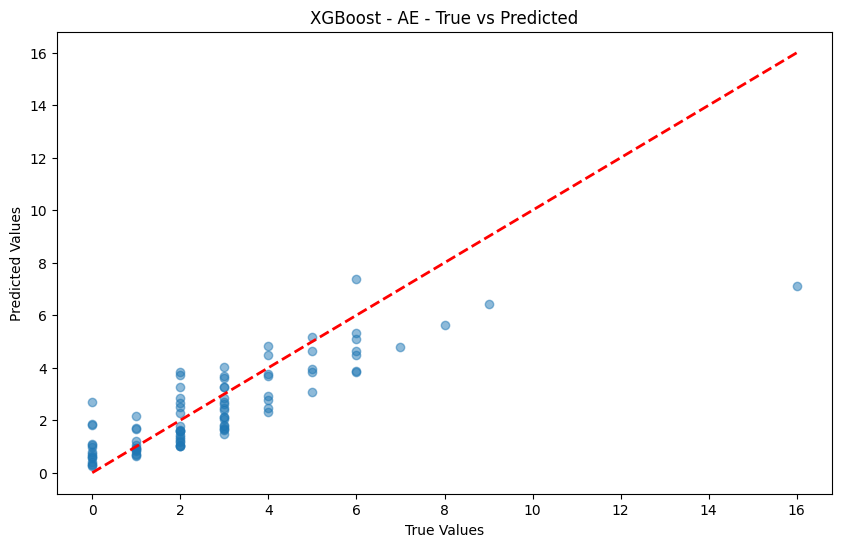

XGBoost Training RMSE: 1.31492173858762
XGBoost Test RMSE: 1.4109304851873092


In [49]:
# XGBoost
xgb_a1, xgb_a1_comparison, train_a1_mse, test_a1_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=143,
        learning_rate=0.023,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.9421,
        colsample_bytree=0.6464,
        gamma=0
    ),
    X_train_a1, y_a1_train, X_val_a1, y_a1_val, X_test_a1, y_a1_test, "XGBoost", "AE"
)

In [50]:
#for AE
xgb_a1_comparison['Predicted'] = np.round(xgb_a1_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_aerelcm': xgb_a1_comparison['Actual'].values, 'predicted_aerelcm': [round(i) for i in xgb_a1_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_aerelcm']-compdf_xgb['predicted_aerelcm'])
print("sum of absolute diff between predicted and actual aerelcm: ",diff_xgb.sum())
print("max value abs diff in aerelcm: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual aerelcm: ",average_deviation)

sum of absolute diff between predicted and actual aerelcm:  86.0
max value abs diff in aerelcm:  9.0
average deviation in predicted and actual aerelcm:  0.9347826086956522


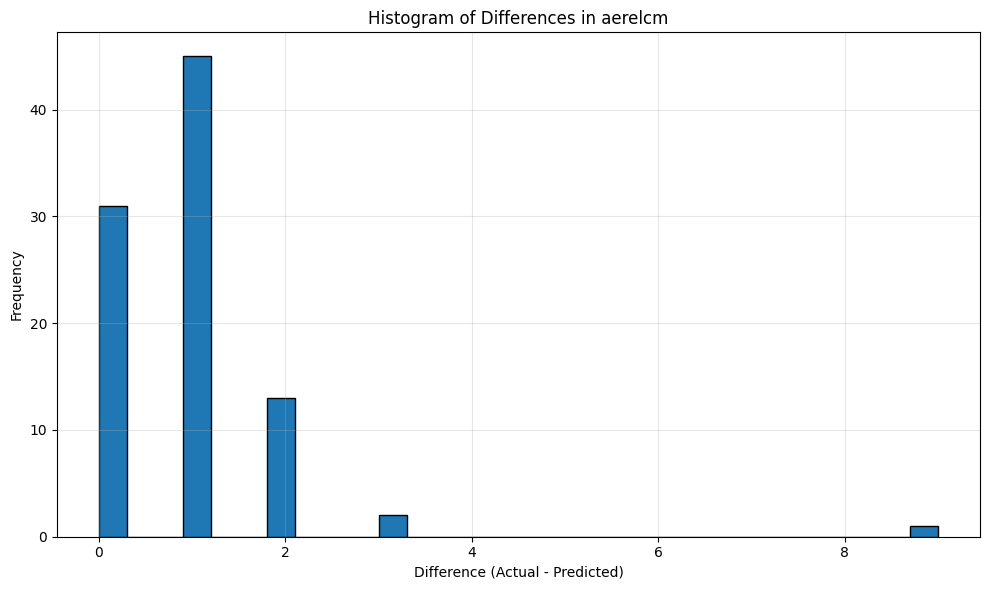

In [51]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in aerelcm')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
X_83 = final_df[common_columns]
y_aerelcm_83 = allpred(xgb_a1,X_83)


Feature 2

In [53]:
X_train_a2, X_temp, y_a2_train, y_a2_temp = train_test_split(X, y_aeact03, test_size=0.33, random_state=42)
X_val_a2, X_test_a2, y_a2_val, y_a2_test = train_test_split(X_temp, y_a2_temp, test_size=0.3, random_state=42)

In [40]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import uniform, randint

# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_a2, y_a2_train)

# best_params = random_search.best_params_
# # best_model = random_search.best_estimator_

In [41]:
# best_params

XGBoost RMSE for AE: 1.7803188921460265


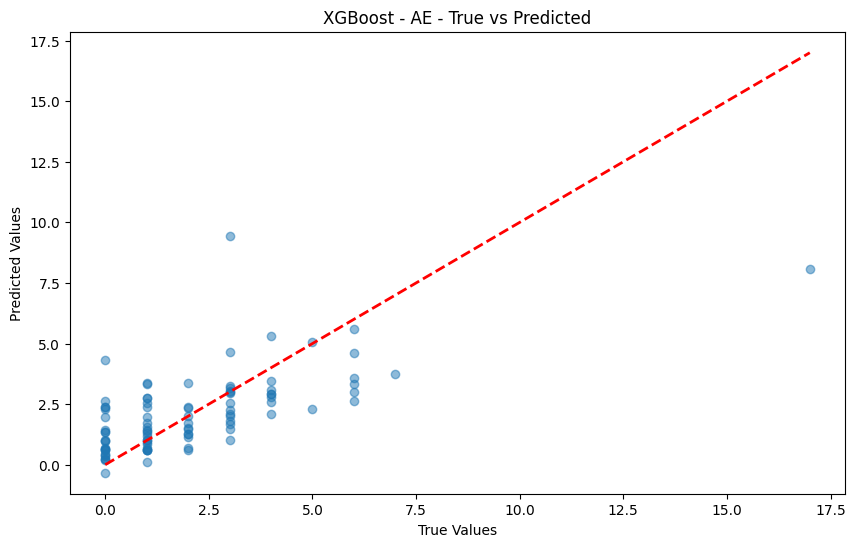

XGBoost Training RMSE: 0.8394544535614625
XGBoost Test RMSE: 1.7803188921460265


In [54]:
# XGBoost
xgb_a2, xgb_a2_comparison, train_a2_mse, test_a2_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=280,
        learning_rate=0.046,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.9627,
        colsample_bytree=0.729,
        gamma=0
    ),
    X_train_a2, y_a2_train, X_val_a2, y_a2_val, X_test_a2, y_a2_test, "XGBoost", "AE"
)

In [55]:
#for AE
xgb_a2_comparison['Predicted'] = np.round(xgb_a2_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_aerelcm': xgb_a2_comparison['Actual'].values, 'predicted_aerelcm': [round(i) for i in xgb_a2_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_aerelcm']-compdf_xgb['predicted_aerelcm'])
print("sum of absolute diff between predicted and actual aerelcm: ",diff_xgb.sum())
print("max value abs diff in aerelcm: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual aerelcm: ",average_deviation)

sum of absolute diff between predicted and actual aerelcm:  101
max value abs diff in aerelcm:  9
average deviation in predicted and actual aerelcm:  1.0978260869565217


In [56]:
y_aeact03_83 = allpred(xgb_a2,X_83)

Feature 3

In [57]:
X_train_a3, X_temp, y_a3_train, y_a3_temp = train_test_split(X, y_aerel, test_size=0.33, random_state=42)
X_val_a3, X_test_a3, y_a3_val, y_a3_test = train_test_split(X_temp, y_a3_temp, test_size=0.3, random_state=42)

In [46]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import uniform, randint

# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_a3, y_a3_train)

# best_params = random_search.best_params_
# # best_model = random_search.best_estimator_

In [54]:
#best_params

{'colsample_bytree': 0.6464290562027665,
 'learning_rate': 0.023800792606525824,
 'max_depth': 3,
 'n_estimators': 143,
 'subsample': 0.9421842336044028}

XGBoost RMSE for AE: 1.600150624052547


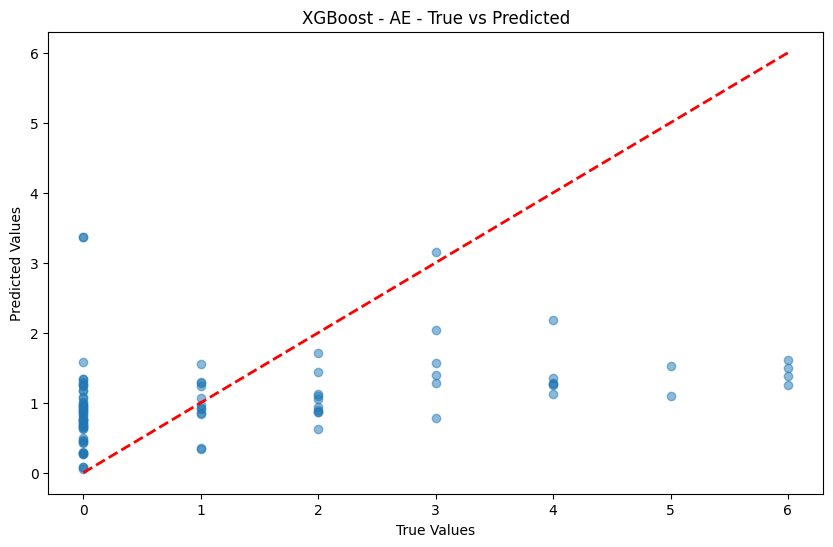

XGBoost Training RMSE: 1.2226951052251411
XGBoost Test RMSE: 1.600150624052547


In [58]:
# XGBoost
xgb_a3, xgb_a3_comparison, train_a3_mse, test_a3_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=143,
        learning_rate=0.023,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.9421,
        colsample_bytree=0.6464,
        gamma=0
    ),
    X_train_a3, y_a3_train, X_val_a3, y_a3_val, X_test_a3, y_a3_test, "XGBoost", "AE"
)

In [59]:
#for AE
xgb_a3_comparison['Predicted'] = np.round(xgb_a3_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_aerelcm': xgb_a3_comparison['Actual'].values, 'predicted_aerelcm': [round(i) for i in xgb_a3_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_aerelcm']-compdf_xgb['predicted_aerelcm'])
print("sum of absolute diff between predicted and actual aerelcm: ",diff_xgb.sum())
print("max value abs diff in aerelcm: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual aerelcm: ",average_deviation)

sum of absolute diff between predicted and actual aerelcm:  107
max value abs diff in aerelcm:  5
average deviation in predicted and actual aerelcm:  1.1630434782608696


In [60]:
y_aerel_83 = allpred(xgb_a3,X_83)

Feature 4

In [61]:
X_train_a4, X_temp, y_a4_train, y_a4_temp = train_test_split(X, y_aefbcdos, test_size=0.33, random_state=42)
X_val_a4, X_test_a4, y_a4_val, y_a4_test = train_test_split(X_temp, y_a4_temp, test_size=0.3, random_state=42)

In [58]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import uniform, randint

# param_distributions = {
#     'n_estimators': randint(50, 700),
#     'learning_rate': uniform(0.01, 0.5),
#     'max_depth': randint(3, 12),
#     'subsample': uniform(0.7, 0.3),
#     'colsample_bytree': uniform(0.7, 0.3)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_a4, y_a4_train)

# best_params = random_search.best_params_
# # best_model = random_search.best_estimator_

In [59]:
#best_params

{'colsample_bytree': 0.9124217733388136,
 'learning_rate': 0.020292247147901225,
 'max_depth': 4,
 'n_estimators': 393,
 'subsample': 0.9497327922401264}

XGBoost RMSE for AE: 307.3683343917548


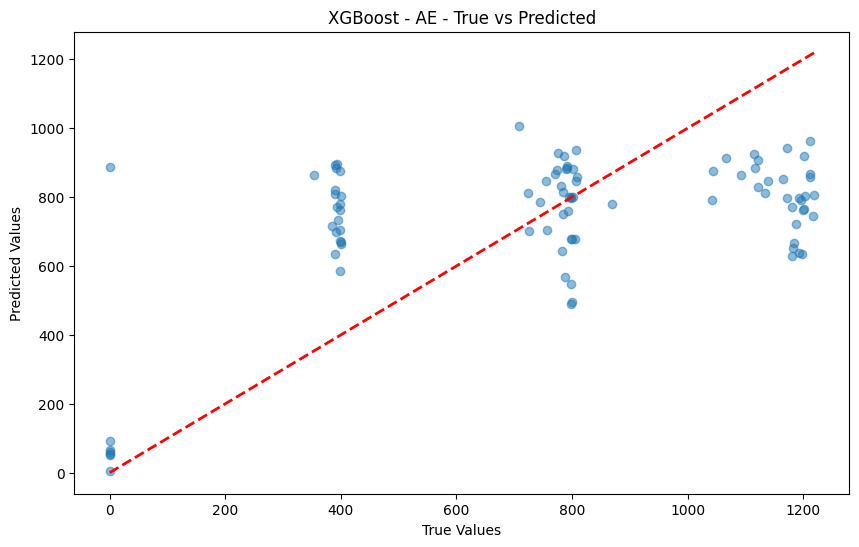

XGBoost Training RMSE: 185.54557846348135
XGBoost Test RMSE: 307.3683343917548


In [62]:
# XGBoost
xgb_a4, xgb_a4_comparison, train_a4_mse, test_a4_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=393,
        learning_rate=0.0203,
        eta=0.1,
        max_depth=4,
        random_state=42,
        eval_metric='rmse',
        subsample=0.9497,
        colsample_bytree=0.9124,
        gamma=0
    ),
    X_train_a4, y_a4_train, X_val_a4, y_a4_val, X_test_a4, y_a4_test, "XGBoost", "AE"
)

In [63]:
#for AE
xgb_a4_comparison['Predicted'] = np.round(xgb_a4_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_aerelcm': xgb_a4_comparison['Actual'].values, 'predicted_aerelcm': [round(i) for i in xgb_a4_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_aerelcm']-compdf_xgb['predicted_aerelcm'])
print("sum of absolute diff between predicted and actual aerelcm: ",diff_xgb.sum())
print("max value abs diff in aerelcm: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual aerelcm: ",average_deviation)

sum of absolute diff between predicted and actual aerelcm:  23141.750260063935
max value abs diff in aerelcm:  888.0
average deviation in predicted and actual aerelcm:  251.5407636963471


In [64]:
y_aefbcdos_83 = allpred(xgb_a4,X_83)

Merging the synthetic data features for 1183 with

In [65]:
y_aefbcdos_83_a = y_aefbcdos_83.rename(columns={'Predictions': 'AEFBCDOS'})
y_aerel_83_a = y_aerel_83.rename(columns={'Predictions': 'AEREL'})
y_aeact03_83_a = y_aeact03_83.rename(columns={'Predictions': 'AEACT03'})
y_aerelcm_83_a = y_aerelcm_83.rename(columns={'Predictions': 'AERELCM'})

# Merge the data frames
merged_df = y_aefbcdos_83_a.merge(y_aerel_83_a, on='SUBJID', how='inner')\
                          .merge(y_aeact03_83_a, on='SUBJID', how='inner')\
                          .merge(y_aerelcm_83_a, on='SUBJID', how='inner')



In [66]:
# First, let's merge X with the previously merged dataframe
merged_df_83 = merged_df.merge(X_83, on='SUBJID', how='inner')

# Now, let's remove duplicate rows based on all columns
merged_df_83 = merged_df_83.drop_duplicates()

# Check the number of unique SUBJID values
print("Number of unique SUBJID values:", merged_df_83['SUBJID'].nunique())

Number of unique SUBJID values: 608


In [67]:
# Get the list of columns in final_merged_df
merged_columns = set(merged_df_83.columns)

# Get the list of columns in fin_df
fin_df_columns = set(fin_df.columns)

# Find the common columns
common_columns = list(merged_columns.intersection(fin_df_columns))

# Print the common columns for verification
print("Common columns:", common_columns)

# Create a new dataframe from fin_df with only the common columns
new_df = fin_df[common_columns].copy()

Common columns: ['AEACT03', 'Total_AE', 'AEREL', 'SUBJID', 'DIAGMONS', 'AGE', 'AEFBCDOS', 'AERELCM', 'B_METANM', 'B_WEIGHT', 'B_HEIGHT']


In [68]:
len(new_df)

925

In [69]:
len(merged_df_83)

608

In [70]:
# Concatenate new_df and final_merged_df
combined_df = pd.concat([new_df, merged_df_83], axis=0, ignore_index=True)

combined_df = combined_df.reset_index(drop=True)

combined_df = combined_df.drop_duplicates(subset='SUBJID', keep='first')

In [71]:
len(combined_df)

1533

# Prediction Model for 1186 and 1183 combined

In [72]:
X_c = combined_df.drop(['Total_AE'], axis=1)
y_ae_c = combined_df['Total_AE']

In [73]:
X_train_ae, X_temp, y_ae_train, y_ae_temp = train_test_split(X_c, y_ae_c, test_size=0.33, random_state=42)
X_val_ae, X_test_ae, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.3, random_state=42)

In [129]:
# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_ae, y_ae_train)

# best_params = random_search.best_params_

# # best_model = random_search.best_estimator_

In [130]:
#best_params

{'colsample_bytree': 0.7678400249711159,
 'learning_rate': 0.08431929685034723,
 'max_depth': 5,
 'n_estimators': 135,
 'subsample': 0.6057573954519023}

XGBoost RMSE for AE: 1.3595752823495875


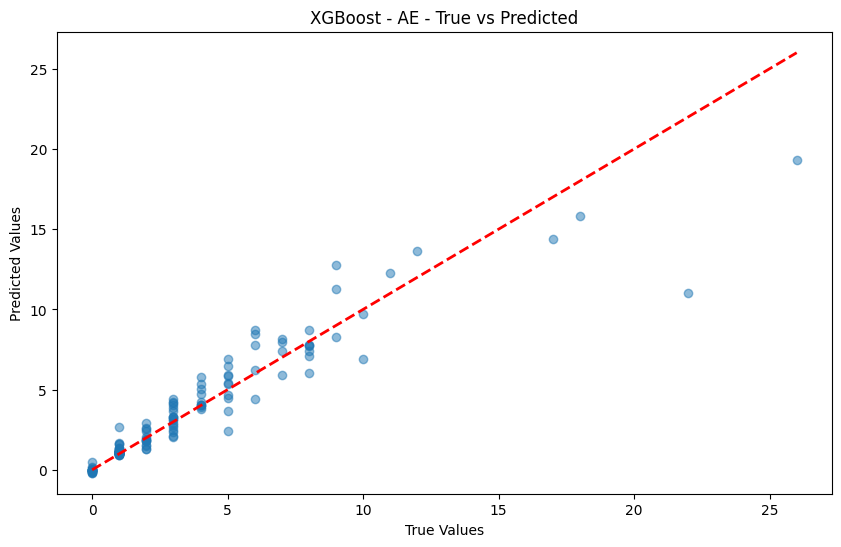

XGBoost Training RMSE: 0.4224381817895999
XGBoost Test RMSE: 1.3595752823495875


In [74]:
# XGBoost
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=135,
        learning_rate=0.084,
        eta=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='rmse',
        subsample=0.605,
        colsample_bytree=0.767,
        gamma=0
    ),
    X_train_ae, y_ae_train, X_val_ae, y_ae_val, X_test_ae, y_ae_test, "XGBoost", "AE"
)

In [75]:
#for AE
xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)

sum of absolute diff between predicted and actual AE:  90.0
max value abs diff in AE:  11.0
average deviation in predicted and actual AE:  0.5921052631578947


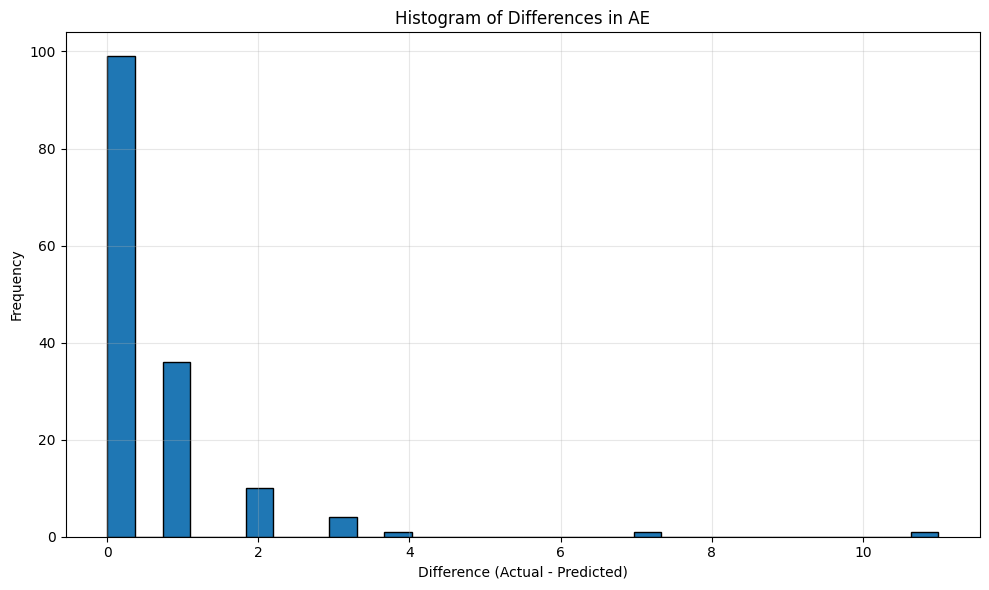

In [76]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

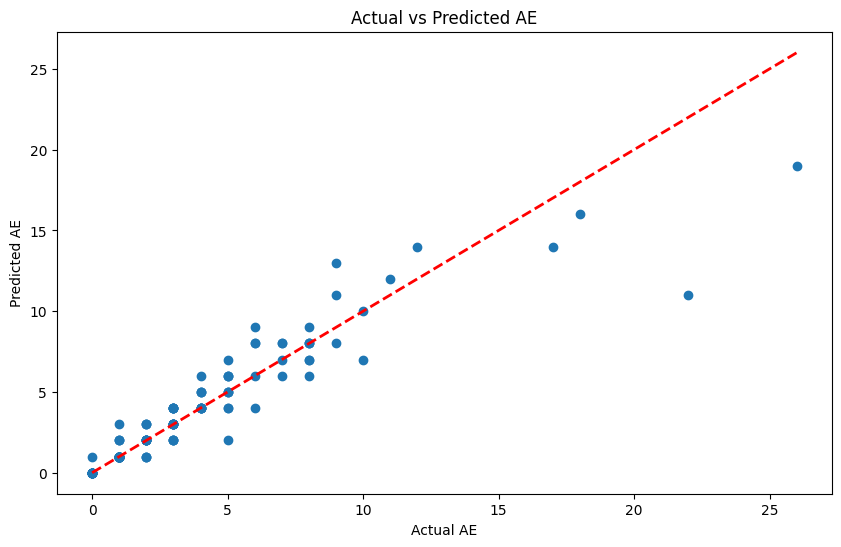

In [77]:
plt.figure(figsize=(10, 6))
plt.scatter(compdf_xgb['actual_AE'], compdf_xgb['predicted_AE'])
plt.plot([compdf_xgb['actual_AE'].min(), compdf_xgb['actual_AE'].max()],
         [compdf_xgb['actual_AE'].min(), compdf_xgb['actual_AE'].max()],
         'r--', lw=2)
plt.xlabel('Actual AE')
plt.ylabel('Predicted AE')
plt.title('Actual vs Predicted AE')
plt.show()

In [79]:
xgb_ae

importances = xgb_ae.feature_importances_
feature_names = X_train_ae.columns 
feature_importances = list(zip(feature_names, importances))
feature_importances_sorted = sorted(feature_importances, key=lambda x: x[1], reverse=True)


for feature, importance in feature_importances_sorted:
    print(f"Feature: {feature}, Importance: {importance}")


Feature: AERELCM, Importance: 0.5675490498542786
Feature: AEACT03, Importance: 0.26201170682907104
Feature: AEREL, Importance: 0.05603686347603798
Feature: AEFBCDOS, Importance: 0.02751748636364937
Feature: SUBJID, Importance: 0.02202434651553631
Feature: B_WEIGHT, Importance: 0.01814238540828228
Feature: B_HEIGHT, Importance: 0.0126386359333992
Feature: B_METANM, Importance: 0.011898064985871315
Feature: AGE, Importance: 0.011149028316140175
Feature: DIAGMONS, Importance: 0.011032477021217346


In [82]:
%pip install -q shap

Note: you may need to restart the kernel to use updated packages.


In [83]:
import shap
explainer = shap.TreeExplainer(xgb_ae)
shap_values = explainer.shap_values(X_train_ae)

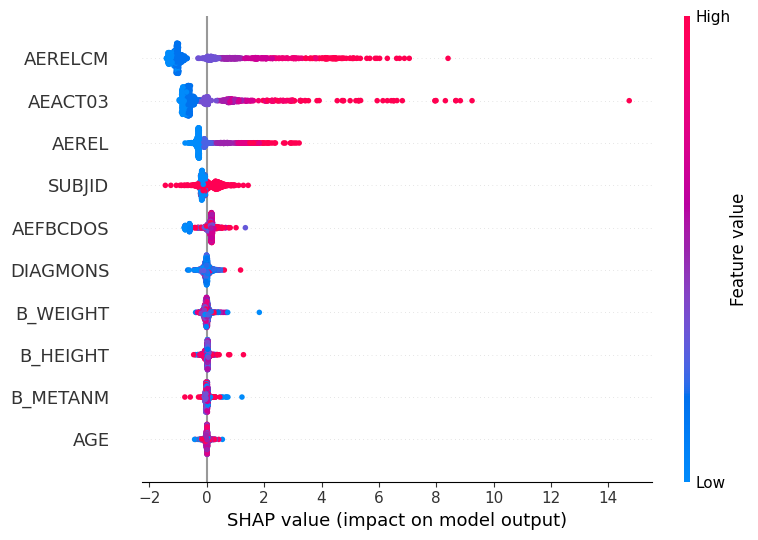

In [84]:
shap.summary_plot(shap_values, X_train_ae)

In [87]:
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame(list(zip(X_train_ae.columns, shap_importance)), columns=['Feature', 'Importance'])

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance)

    Feature  Importance
6   AERELCM    1.353304
0   AEACT03    0.935461
1     AEREL    0.418309
2    SUBJID    0.242163
5  AEFBCDOS    0.232015
3  DIAGMONS    0.079514
8  B_WEIGHT    0.065692
9  B_HEIGHT    0.056645
7  B_METANM    0.038516
4       AGE    0.036961


# Month 2 : data merge and predictions


In [88]:
m2_ae = ae_data[ae_data['ae_month'] == 'month2'].copy()
m2_ae.drop(columns=['ae_month',],inplace=True)

fin_df = pd.merge(demobl,medhist,on=['SUBJID'],how='left')
fin_df = pd.merge(fin_df,m2_ae,on=['SUBJID'],how='inner')
fin_df.columns = fin_df.columns.str.replace(" ", "_")
fin_df.columns = fin_df.columns.str.replace("<", "lessthan")
fin_df.drop(columns=['BIOPF', 'BIOPHF', 'BIOPRS', 'BIOPEF'],inplace=True)
fin_df.drop(columns=['Unnamed:_0'],inplace=True)

In [89]:
fin_df.rename(columns={'total_AE': 'Total_AE'}, inplace=True)

In [90]:
aa = fin_df[top_features_ae]

In [91]:
common_columns = final_df.columns.intersection(aa.columns)

print("Common columns:", common_columns.tolist())

Common columns: ['SUBJID', 'Total_AE', 'DIAGMONS', 'AGE', 'B_WEIGHT', 'B_HEIGHT', 'B_METANM']


In [92]:
final_df = reset_finaldf()

In [93]:
final_df = final_df[final_df['Month']=='month2']
X_83 = final_df[common_columns]

In [94]:
y_aerelcm_83 = allpred(xgb_a1,X_83)
y_aeact03_83 = allpred(xgb_a2,X_83)
y_aerel_83 = allpred(xgb_a3,X_83)
y_aefbcdos_83 = allpred(xgb_a4,X_83)

In [95]:
y_aefbcdos_83_a = y_aefbcdos_83.rename(columns={'Predictions': 'AEFBCDOS'})
y_aerel_83_a = y_aerel_83.rename(columns={'Predictions': 'AEREL'})
y_aeact03_83_a = y_aeact03_83.rename(columns={'Predictions': 'AEACT03'})
y_aerelcm_83_a = y_aerelcm_83.rename(columns={'Predictions': 'AERELCM'})

# Merge the data frames
merged_df = y_aefbcdos_83_a.merge(y_aerel_83_a, on='SUBJID', how='inner')\
                          .merge(y_aeact03_83_a, on='SUBJID', how='inner')\
                          .merge(y_aerelcm_83_a, on='SUBJID', how='inner')

In [96]:
merged_df_83 = merged_df.merge(X_83, on='SUBJID', how='inner')
merged_df_83 = merged_df_83.drop_duplicates()
print("Number of unique SUBJID values:", merged_df_83['SUBJID'].nunique())

Number of unique SUBJID values: 608


In [97]:
merged_columns = set(merged_df_83.columns)
fin_df_columns = set(fin_df.columns)
common_columns = list(merged_columns.intersection(fin_df_columns))
print("Common columns:", common_columns)
new_df = fin_df[common_columns].copy()

Common columns: ['AEACT03', 'Total_AE', 'AEREL', 'SUBJID', 'DIAGMONS', 'AGE', 'AEFBCDOS', 'AERELCM', 'B_METANM', 'B_WEIGHT', 'B_HEIGHT']


In [98]:
# Concatenate new_df and final_merged_df
combined_df = pd.concat([new_df, merged_df_83], axis=0, ignore_index=True)

combined_df = combined_df.reset_index(drop=True)

combined_df = combined_df.drop_duplicates(subset='SUBJID', keep='first')

prediction

In [99]:
X_c = combined_df.drop(['Total_AE'], axis=1)
y_ae_c = combined_df['Total_AE']

In [100]:
X_train_ae, X_temp, y_ae_train, y_ae_temp = train_test_split(X_c, y_ae_c, test_size=0.33, random_state=42)
X_val_ae, X_test_ae, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.3, random_state=42)

In [ ]:
# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_ae, y_ae_train)

# best_params = random_search.best_params_

# # best_model = random_search.best_estimator_

In [ ]:
# best_params

XGBoost RMSE for AE: 1.4519727640832878


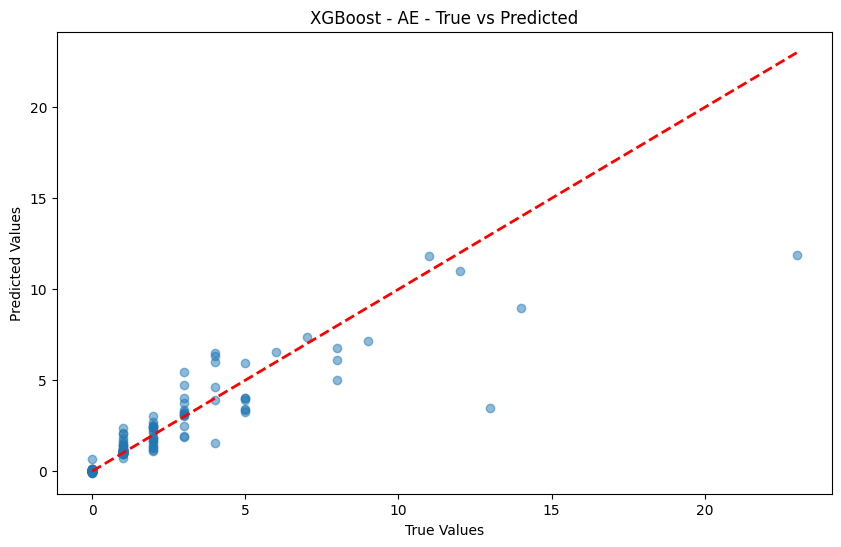

XGBoost Training RMSE: 0.28363663767843006
XGBoost Test RMSE: 1.4519727640832878


In [101]:
# XGBoost
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=135,
        learning_rate=0.084,
        eta=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='rmse',
        subsample=0.605,
        colsample_bytree=0.767,
        gamma=0
    ),
    X_train_ae, y_ae_train, X_val_ae, y_ae_val, X_test_ae, y_ae_test, "XGBoost", "AE"
)

In [102]:
#for AE
xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)

sum of absolute diff between predicted and actual AE:  80.0
max value abs diff in AE:  11.0
average deviation in predicted and actual AE:  0.5263157894736842


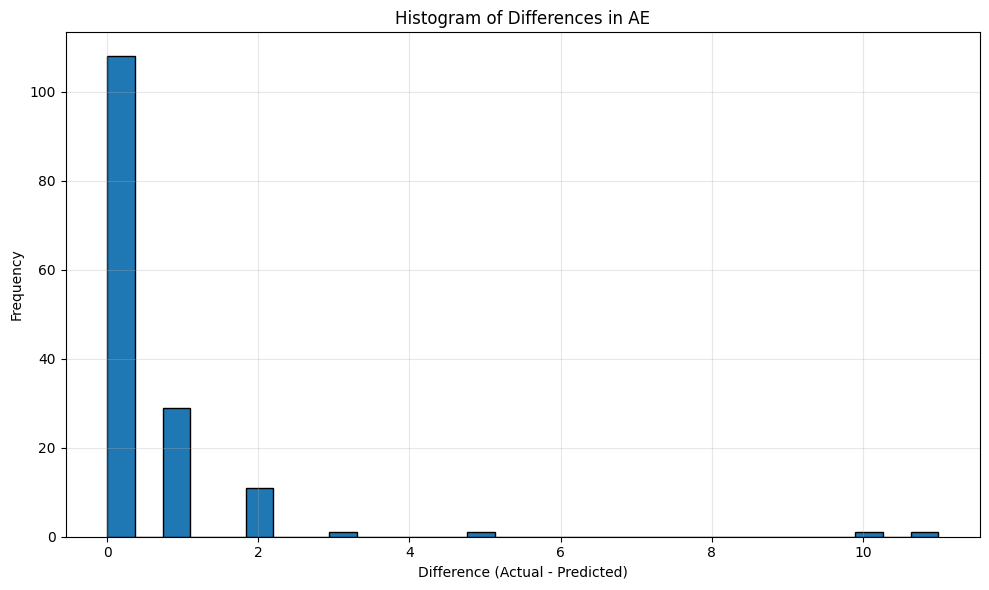

In [103]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

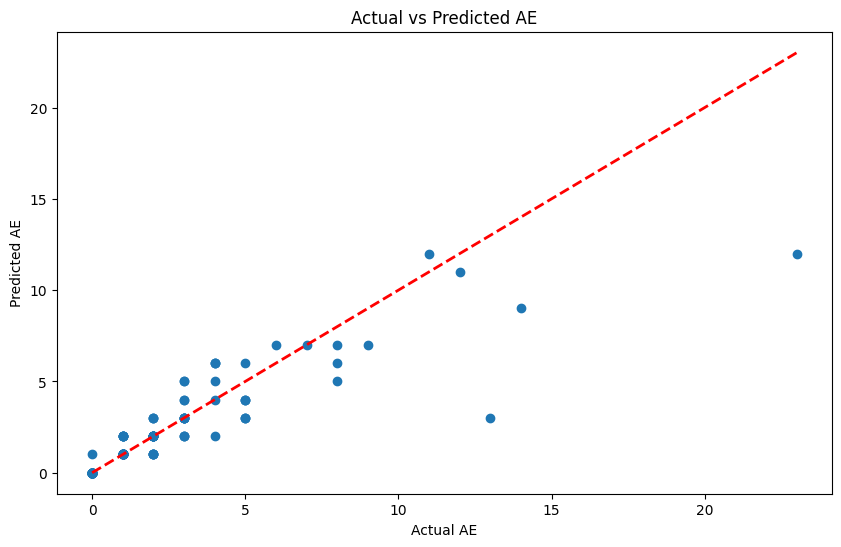

In [104]:
plt.figure(figsize=(10, 6))
plt.scatter(compdf_xgb['actual_AE'], compdf_xgb['predicted_AE'])
plt.plot([compdf_xgb['actual_AE'].min(), compdf_xgb['actual_AE'].max()],
         [compdf_xgb['actual_AE'].min(), compdf_xgb['actual_AE'].max()],
         'r--', lw=2)
plt.xlabel('Actual AE')
plt.ylabel('Predicted AE')
plt.title('Actual vs Predicted AE')
plt.show()

In [105]:
importances = xgb_ae.feature_importances_
feature_names = X_train_ae.columns 
feature_importances = list(zip(feature_names, importances))
feature_importances_sorted = sorted(feature_importances, key=lambda x: x[1], reverse=True)


for feature, importance in feature_importances_sorted:
    print(f"Feature: {feature}, Importance: {importance}")

Feature: AERELCM, Importance: 0.4899267852306366
Feature: AEACT03, Importance: 0.2843717634677887
Feature: AEFBCDOS, Importance: 0.05658532679080963
Feature: AEREL, Importance: 0.056553494185209274
Feature: AGE, Importance: 0.020909739658236504
Feature: SUBJID, Importance: 0.0202922560274601
Feature: B_METANM, Importance: 0.01965985633432865
Feature: B_HEIGHT, Importance: 0.018827594816684723
Feature: B_WEIGHT, Importance: 0.01767878793179989
Feature: DIAGMONS, Importance: 0.015194348059594631


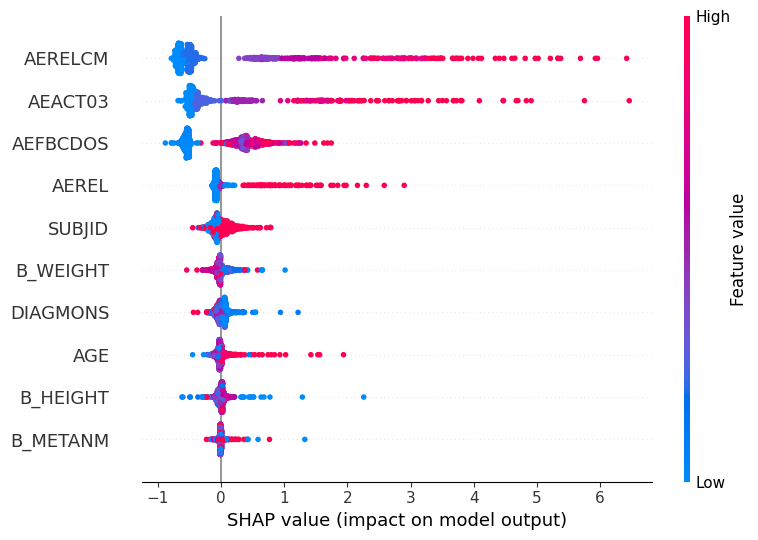

In [106]:
import shap
explainer = shap.TreeExplainer(xgb_ae)
shap_values = explainer.shap_values(X_train_ae)
shap.summary_plot(shap_values, X_train_ae)

In [107]:
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame(list(zip(X_train_ae.columns, shap_importance)), columns=['Feature', 'Importance'])
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
print(feature_importance)

    Feature  Importance
6   AERELCM    0.866037
0   AEACT03    0.626615
5  AEFBCDOS    0.473921
1     AEREL    0.156080
2    SUBJID    0.110132
8  B_WEIGHT    0.067188
3  DIAGMONS    0.064287
4       AGE    0.059214
9  B_HEIGHT    0.049070
7  B_METANM    0.025326


# ALL Months Together

In [110]:
final_df = reset_finaldf()

In [111]:
# Group by 'SUBJID' and sum 'Total_AE'
final_df_all = final_df.groupby('SUBJID').agg({
    'Total_AE': 'sum',
    # For all other columns, we'll take the first value
    # as they should be the same for each SUBJID
    **{col: 'first' for col in final_df.columns if col not in ['SUBJID', 'Month', 'Total_AE']}
})

#Reset the index to make 'SUBJID' a column again
final_df_all = final_df_all.reset_index()

In [112]:
# Group by SUBJID and sum total_AE and total_SAE for all months
new_df = ae_data.groupby('SUBJID').agg({
    'total_AE': 'sum',
    'total_SAE': 'sum'
})

# Get one row per SUBJID with all other columns (except ae_month)
other_columns = ae_data.drop(['ae_month', 'total_AE', 'total_SAE'], axis=1).drop_duplicates(subset=['SUBJID'])

# Merge the summed totals with the other columns
new_df = other_columns.merge(new_df, on='SUBJID', how='left')

In [113]:
fin_df_n = pd.merge(demobl,medhist,on=['SUBJID'],how='left')
fin_df_n = pd.merge(fin_df_n,new_df,on=['SUBJID'],how='inner')
fin_df_n.columns = fin_df_n.columns.str.replace(" ", "_")
fin_df_n.columns = fin_df_n.columns.str.replace("<", "lessthan")
fin_df_n.drop(columns=['BIOPF', 'BIOPHF', 'BIOPRS', 'BIOPEF'],inplace=True)


In [114]:
fin_df_n.rename(columns={'total_AE': 'Total_AE'}, inplace=True)

In [115]:
aa = fin_df_n[top_features_ae]
common_columns = final_df_all.columns.intersection(aa.columns)

print("Common columns:", common_columns.tolist())

Common columns: ['SUBJID', 'Total_AE', 'DIAGMONS', 'AGE', 'B_WEIGHT', 'B_HEIGHT', 'B_METANM']


In [116]:
X_83 = final_df_all[common_columns]

In [117]:
y_aerelcm_83 = allpred(xgb_a1,X_83)
y_aeact03_83 = allpred(xgb_a2,X_83)
y_aerel_83 = allpred(xgb_a3,X_83)
y_aefbcdos_83 = allpred(xgb_a4,X_83)

In [118]:
y_aefbcdos_83_a = y_aefbcdos_83.rename(columns={'Predictions': 'AEFBCDOS'})
y_aerel_83_a = y_aerel_83.rename(columns={'Predictions': 'AEREL'})
y_aeact03_83_a = y_aeact03_83.rename(columns={'Predictions': 'AEACT03'})
y_aerelcm_83_a = y_aerelcm_83.rename(columns={'Predictions': 'AERELCM'})

# Merge the data frames
merged_df = y_aefbcdos_83_a.merge(y_aerel_83_a, on='SUBJID', how='inner')\
                          .merge(y_aeact03_83_a, on='SUBJID', how='inner')\
                          .merge(y_aerelcm_83_a, on='SUBJID', how='inner')

In [119]:
merged_df_83 = merged_df.merge(X_83, on='SUBJID', how='inner')
merged_df_83 = merged_df_83.drop_duplicates()
print("Number of unique SUBJID values:", merged_df_83['SUBJID'].nunique())

Number of unique SUBJID values: 608


In [120]:
merged_columns = set(merged_df_83.columns)
fin_df_columns = set(fin_df_n.columns)
common_columns = list(merged_columns.intersection(fin_df_columns))
print("Common columns:", common_columns)
new_df = fin_df_n[common_columns].copy()

Common columns: ['AEACT03', 'Total_AE', 'AEREL', 'SUBJID', 'DIAGMONS', 'AGE', 'AEFBCDOS', 'AERELCM', 'B_METANM', 'B_WEIGHT', 'B_HEIGHT']


In [121]:
# Concatenate new_df and final_merged_df
combined_df = pd.concat([new_df, merged_df_83], axis=0, ignore_index=True)

combined_df = combined_df.reset_index(drop=True)

combined_df = combined_df.drop_duplicates(subset='SUBJID', keep='first')

In [122]:
combined_df

,AEACT03,Total_AE,AEREL,SUBJID,DIAGMONS,AGE,AEFBCDOS,AERELCM,B_METANM,B_WEIGHT,B_HEIGHT
0,1.0,5.0,2.0,201001001,9.540984,54.0,399.785107,1.0,4.0,80.0,182.0
1,2.0,3.0,2.0,201001002,6.131148,66.0,1181.520479,0.0,3.0,93.0,178.0
2,0.0,15.0,0.0,201001004,12.327869,58.0,0.000000,0.0,3.0,62.0,164.0
3,3.0,12.0,3.0,201001005,9.803279,75.0,1191.018084,1.0,2.0,106.0,188.0
4,1.0,1.0,0.0,201001006,2.885246,52.0,297.683363,1.0,3.0,130.0,200.0
...,...,...,...,...,...,...,...,...,...,...,...
1528,1.0,3.0,1.0,1169,0.459016,61.0,851.000000,2.0,3.0,66.5,168.0
1529,2.0,3.0,1.0,1171,2.065574,72.0,567.000000,2.0,3.0,53.0,152.0
1530,1.0,3.0,1.0,1172,6.655738,72.0,818.000000,2.0,2.0,67.3,165.0
1531,1.0,3.0,1.0,1181,65.081967,36.0,485.000000,2.0,4.0,111.0,189.0


In [123]:
combined_df.drop('SUBJID', axis=1,inplace=True)

In [124]:
X_c = combined_df.drop(['Total_AE'], axis=1)
y_ae_c = combined_df['Total_AE']

In [125]:
X_train_ae, X_temp, y_ae_train, y_ae_temp = train_test_split(X_c, y_ae_c, test_size=0.33, random_state=42)
X_val_ae, X_test_ae, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.3, random_state=42)

In [127]:
# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_ae, y_ae_train)

# best_params = random_search.best_params_
# best_params
# # best_model = random_search.best_estimator_

XGBoost RMSE for AE: 17.874705484374378


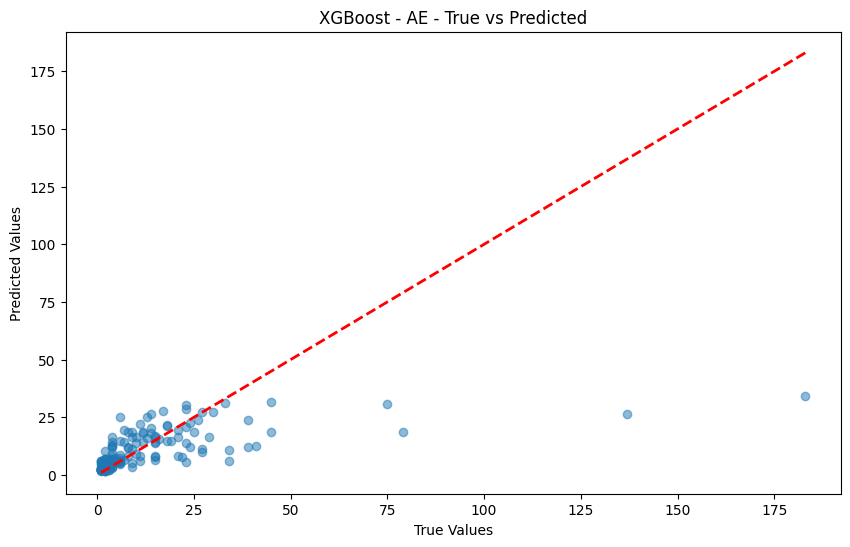

XGBoost Training RMSE: 7.5807889202246574
XGBoost Test RMSE: 17.874705484374378


In [128]:
# XGBoost
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=143,
        learning_rate=0.023,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.94,
        colsample_bytree=0.6464,
        gamma=0
    ),
    X_train_ae, y_ae_train, X_val_ae, y_ae_val, X_test_ae, y_ae_test, "XGBoost", "AE"
)

In [129]:
#for AE
xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)

sum of absolute diff between predicted and actual AE:  1081.0
max value abs diff in AE:  149.0
average deviation in predicted and actual AE:  7.1118421052631575


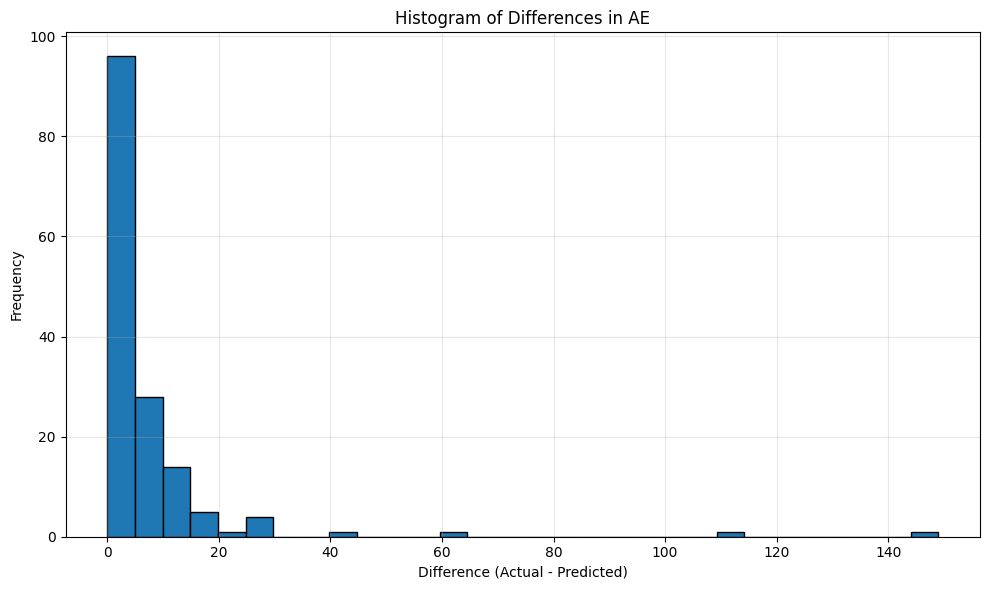

In [130]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

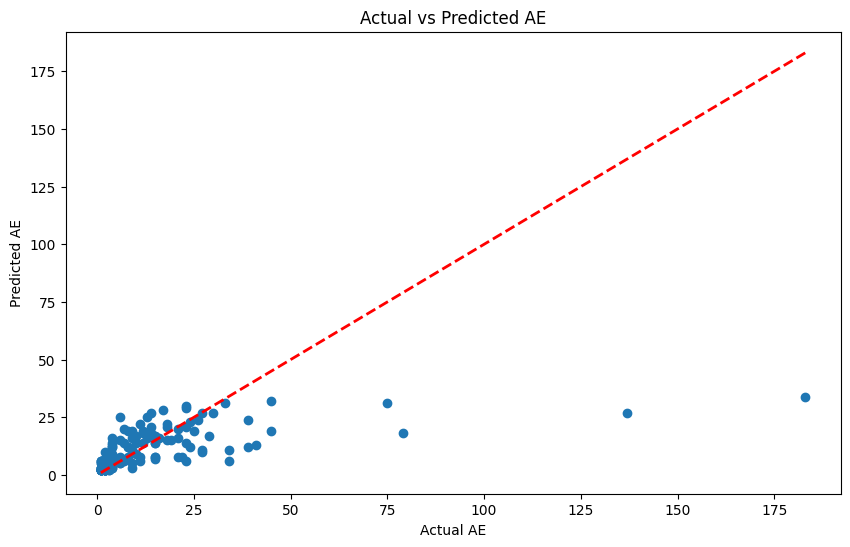

In [131]:
plt.figure(figsize=(10, 6))
plt.scatter(compdf_xgb['actual_AE'], compdf_xgb['predicted_AE'])
plt.plot([compdf_xgb['actual_AE'].min(), compdf_xgb['actual_AE'].max()],
         [compdf_xgb['actual_AE'].min(), compdf_xgb['actual_AE'].max()],
         'r--', lw=2)
plt.xlabel('Actual AE')
plt.ylabel('Predicted AE')
plt.title('Actual vs Predicted AE')
plt.show()

In [132]:
importances = xgb_ae.feature_importances_
feature_names = X_train_ae.columns 
feature_importances = list(zip(feature_names, importances))
feature_importances_sorted = sorted(feature_importances, key=lambda x: x[1], reverse=True)


for feature, importance in feature_importances_sorted:
    print(f"Feature: {feature}, Importance: {importance}")

Feature: AERELCM, Importance: 0.3047192692756653
Feature: AEACT03, Importance: 0.236341193318367
Feature: AEREL, Importance: 0.14818020164966583
Feature: DIAGMONS, Importance: 0.0842253714799881
Feature: AEFBCDOS, Importance: 0.06693357974290848
Feature: B_METANM, Importance: 0.04364090412855148
Feature: B_HEIGHT, Importance: 0.04220113903284073
Feature: B_WEIGHT, Importance: 0.041386716067790985
Feature: AGE, Importance: 0.0323716476559639


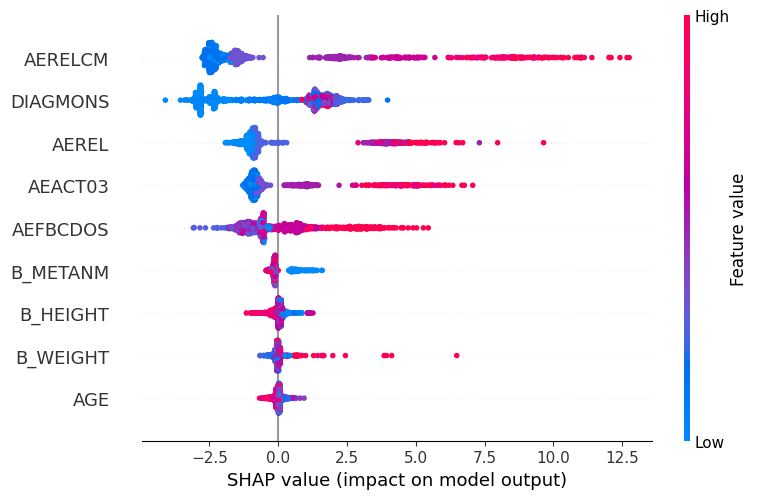

In [133]:
import shap
explainer = shap.TreeExplainer(xgb_ae)
shap_values = explainer.shap_values(X_train_ae)
shap.summary_plot(shap_values, X_train_ae)

In [134]:
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame(list(zip(X_train_ae.columns, shap_importance)), columns=['Feature', 'Importance'])
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
print(feature_importance)

    Feature  Importance
5   AERELCM    3.024065
2  DIAGMONS    1.770192
1     AEREL    1.585230
0   AEACT03    1.332590
4  AEFBCDOS    1.141131
6  B_METANM    0.256559
8  B_HEIGHT    0.158606
7  B_WEIGHT    0.116038
3       AGE    0.102017
